## *Experiment 02: Huấn luyện mô hình Deep Learning cho bộ dữ liệu FiveDataset*

- Đọc dữ liệu gene expression
- Kiểm tra phân bố lớp
- Chia train / validation / test
- Tiền xử lý dữ liệu để giảm số chiều
- Xử lý mất cân bằng lớp
- Huấn luyện mô hình MLP bằng PyTorch
- Đánh giá bằng Accuracy, Macro F1, AUC và Confusion Matrix


### Bước 1. Import thư viện và khởi tạo thư mục làm việc

In [1]:

import os
import re
import random
import zipfile
import joblib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def get_next_run_dir(model_root: Path) -> Path:
    model_root.mkdir(parents=True, exist_ok=True)
    pattern = re.compile(r"run(\d+)$")
    nums = []
    for p in model_root.iterdir():
        if p.is_dir():
            m = pattern.match(p.name)
            if m:
                nums.append(int(m.group(1)))
    next_num = 1 if not nums else max(nums) + 1
    return model_root / f"run{next_num:02d}"

def load_five_dataset(data_dir: Path, class_col: str = "Class") -> pd.DataFrame:
    csv_path = data_dir / "FiveDataset.csv"
    zip_path = data_dir / "FiveDataset.zip"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            target = None
            for name in zf.namelist():
                if name.lower().endswith(".csv") and "fivedataset" in name.lower():
                    target = name
                    break
            if target is None:
                candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
                if not candidates:
                    raise FileNotFoundError("Không tìm thấy file CSV trong FiveDataset.zip")
                target = candidates[0]
            with zf.open(target) as f:
                df = pd.read_csv(f)
    else:
        raise FileNotFoundError("Không tìm thấy FiveDataset.csv hoặc FiveDataset.zip trong data/raw")

    if class_col not in df.columns:
        raise ValueError(f"Không tìm thấy cột nhãn '{class_col}'")
    return df

seed_everything(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"

EXPERIMENT_ROOT = PROJECT_ROOT / "outputs" / "ex02"
RUN_DIR = get_next_run_dir(EXPERIMENT_ROOT)

FIG_DIR = RUN_DIR / "figures"
METRIC_DIR = RUN_DIR / "metrics"
MODEL_DIR = RUN_DIR / "models"

for d in [FIG_DIR, METRIC_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("EXPERIMENT_ROOT:", EXPERIMENT_ROOT)
print("RUN_DIR:", RUN_DIR)


PROJECT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl
DATA_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\data\raw
EXPERIMENT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex02
RUN_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex02\run01


### Bước 2. Khai báo tham số cấu hình


In [2]:

LABEL_COL = "Class"
DROP_COLS = ["Unnamed: 0"]

TEST_SIZE = 0.15
VAL_SIZE = 0.15
TRAIN_SIZE = 0.70

TOP_VAR_GENES = 5000      # giữ lại 5000 gene có độ biến thiên cao nhất
TOP_K_FEATURES = 2000     # tiếp tục chọn 2000 gene tốt nhất bằng ANOVA F-test

BATCH_SIZE = 64
EPOCHS = 80
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 12
DROPOUT = 0.35

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị đang dùng:", DEVICE)


Thiết bị đang dùng: cpu


### Bước 3. Đọc dữ liệu và quan sát nhanh cấu trúc

Nội dung:
- đọc file FiveDataset.csv
- xác định cột nhãn
- lấy ra các cột gene expression
- in ra kích thước dữ liệu để kiểm tra ban đầu


In [3]:

df = load_five_dataset(DATA_DIR, class_col=LABEL_COL)

print("Kích thước dữ liệu:", df.shape)
print("5 dòng đầu:")
display(df.head())

all_cols = df.columns.tolist()
gene_cols = [c for c in all_cols if c not in DROP_COLS + [LABEL_COL]]

print("Số cột gene:", len(gene_cols))
print("Phân bố lớp ban đầu:")
print(df[LABEL_COL].value_counts())


Kích thước dữ liệu: (2521, 21357)
5 dòng đầu:


,Unnamed: 0,DDR1,RFC2,HSPA6,PAX8,GUCA1A,UBA7,THRA,PTPN21,CCL5,...,NQO2-AS1,ITGB1-DT,TNFRSF10A-DT,LOC400499,GALR3,ZNF710-AS1,SAP25,TMEM231,LOC100505915,Class
0,GSM329407,5.849528,7.511939,7.226272,4.658426,4.386529,8.436415,4.734517,3.706727,10.559860,...,3.414406,4.034259,4.592081,6.340251,5.661825,6.559102,6.754030,3.918783,6.285588,ALL
1,GSM329408,6.766342,8.540821,6.708342,4.799562,4.259775,8.387226,5.014696,3.708090,6.340428,...,3.644112,4.364029,4.299601,6.040011,5.552325,6.617199,6.298633,3.888387,6.737579,ALL
2,GSM329409,6.338627,6.997434,5.592194,4.880400,4.254007,7.942577,5.260786,3.856917,8.051982,...,3.662437,4.082659,4.490583,6.300898,6.001656,7.018180,7.219880,4.602060,6.910033,ALL
3,GSM329410,6.344920,7.756993,4.751323,5.105609,4.446036,6.644163,4.860472,3.955169,6.869770,...,3.630987,4.092957,4.837855,6.228940,5.196468,6.682549,6.069478,3.397362,6.560738,ALL
4,GSM329411,6.248682,6.464299,6.076184,4.680320,4.221692,8.126787,5.302099,4.046247,9.666565,...,3.306647,4.870442,4.304849,6.223652,6.146207,6.158043,6.823452,3.839242,6.455058,ALL


Số cột gene: 21355
Phân bố lớp ban đầu:
Class
ALL        749
AML        682
CLL        448
MDS        389
CML        162
Healthy     91
Name: count, dtype: int64


### Bước 4. Kiểm tra phân bố lớp và mức độ chênh lệch mẫu

Cell này rất quan trọng vì giúp xác định:
- lớp nào nhiều mẫu
- lớp nào ít mẫu
- mức độ mất cân bằng dữ liệu có nghiêm trọng hay không

Biểu đồ này có thể đưa vào báo cáo để giải thích vì sao phải xử lý class imbalance.


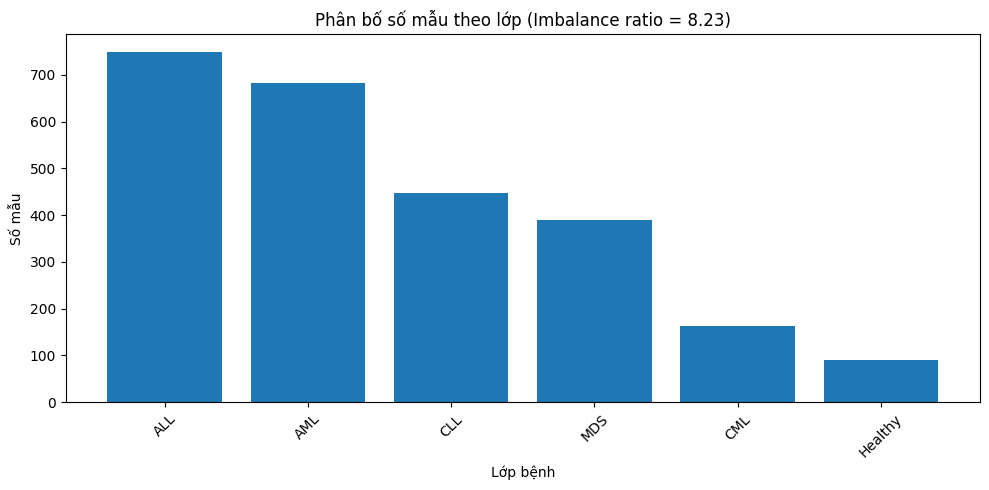

In [4]:

class_counts = df[LABEL_COL].value_counts().sort_values(ascending=False)
imbalance_ratio = class_counts.max() / class_counts.min()

plt.figure(figsize=(10, 5))
plt.bar(class_counts.index, class_counts.values)
plt.title(f"Phân bố số mẫu theo lớp (Imbalance ratio = {imbalance_ratio:.2f})")
plt.xlabel("Lớp bệnh")
plt.ylabel("Số mẫu")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

class_counts.to_csv(METRIC_DIR / "class_distribution_6class.csv")


### Bước 5. Tách đặc trưng và nhãn, sau đó chia train / validation / test

Cell này dùng chia dữ liệu theo tỉ lệ:
- Train: 70%
- Validation: 15%
- Test: 15%

Việc chia có dùng stratify để giữ tương đối ổn định phân bố lớp giữa các tập.


In [5]:

X = df[gene_cols].astype(np.float32).values
y = df[LABEL_COL].astype(str).values

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
class_names = list(label_encoder.classes_)
num_classes = len(class_names)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y_encoded,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=42,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)
print("Các lớp:", class_names)


Train: (1764, 21355) (1764,)
Validation: (378, 21355) (378,)
Test: (379, 21355) (379,)
Các lớp: ['ALL', 'AML', 'CLL', 'CML', 'Healthy', 'MDS']


### Bước 6. Kiểm tra lại phân bố lớp sau khi chia dữ liệu


In [6]:

split_summary = pd.DataFrame({
    "train": pd.Series(y_train).value_counts().sort_index(),
    "val": pd.Series(y_val).value_counts().sort_index(),
    "test": pd.Series(y_test).value_counts().sort_index()
})

split_summary.index = [class_names[i] for i in split_summary.index]
display(split_summary)

split_summary.to_csv(METRIC_DIR / "split_class_distribution.csv")


,train,val,test
ALL,524,112,113
AML,477,102,103
CLL,314,67,67
CML,113,25,24
Healthy,64,14,13
MDS,272,58,59


### Bước 7. Tiền xử lý dữ liệu để giảm số chiều

Dữ liệu gene expression có số chiều rất lớn nên nếu train trực tiếp sẽ rất dễ:
- chậm
- overfitting
- khó hội tụ

Vì vậy ở đây ta làm 3 bước:
1. Giữ lại các gene có độ biến thiên cao
2. Chuẩn hóa dữ liệu bằng StandardScaler
3. Chọn tiếp ra K gene tốt nhất bằng ANOVA F-test

Lưu ý: tất cả bước fit chỉ thực hiện trên tập train để tránh rò rỉ dữ liệu.


In [7]:

# 1) Giữ lại TOP_VAR_GENES gene có độ biến thiên cao nhất trên train
gene_variances = np.var(X_train, axis=0)
top_var_idx = np.argsort(gene_variances)[::-1][:TOP_VAR_GENES]

X_train_var = X_train[:, top_var_idx]
X_val_var = X_val[:, top_var_idx]
X_test_var = X_test[:, top_var_idx]

selected_var_gene_names = [gene_cols[i] for i in top_var_idx]

# 2) Chuẩn hóa
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_var)
X_val_scaled = scaler.transform(X_val_var)
X_test_scaled = scaler.transform(X_test_var)

# 3) Chọn tiếp TOP_K_FEATURES gene tốt nhất
k_features = min(TOP_K_FEATURES, X_train_scaled.shape[1])
selector = SelectKBest(score_func=f_classif, k=k_features)

X_train_final = selector.fit_transform(X_train_scaled, y_train)
X_val_final = selector.transform(X_val_scaled)
X_test_final = selector.transform(X_test_scaled)

selected_k_idx = selector.get_support(indices=True)
selected_gene_names = [selected_var_gene_names[i] for i in selected_k_idx]

print("Shape train ban đầu:", X_train.shape)
print("Sau variance filter :", X_train_var.shape)
print("Sau SelectKBest     :", X_train_final.shape)

pd.DataFrame({"selected_gene": selected_gene_names}).to_csv(
    METRIC_DIR / "selected_genes.csv", index=False
)

joblib.dump(scaler, MODEL_DIR / "scaler.pkl")
joblib.dump(selector, MODEL_DIR / "selector.pkl")
joblib.dump(label_encoder, MODEL_DIR / "label_encoder.pkl")
joblib.dump(top_var_idx, MODEL_DIR / "top_var_idx.pkl")


Shape train ban đầu: (1764, 21355)
Sau variance filter : (1764, 5000)
Sau SelectKBest     : (1764, 2000)


['c:\\Users\\Minh Chau\\Desktop\\DACN_Leukemia-gene-expression-dl\\DACN_Leukemia-gene-expression-dl\\outputs\\ex02\\run01\\models\\top_var_idx.pkl']

### Bước 8. Tạo Dataset và DataLoader cho PyTorch

Cell này biến dữ liệu numpy thành dataset cho PyTorch.
Ngoài ra, để xử lý mất cân bằng lớp ở tập train, ta dùng WeightedRandomSampler.


In [8]:

class GeneExpressionDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = GeneExpressionDataset(X_train_final, y_train)
val_dataset = GeneExpressionDataset(X_val_final, y_val)
test_dataset = GeneExpressionDataset(X_test_final, y_test)

train_class_counts = np.bincount(y_train)
class_sample_weights = 1.0 / train_class_counts
sample_weights = class_sample_weights[y_train]
sample_weights = torch.DoubleTensor(sample_weights)

train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

loss_class_weights = len(y_train) / (num_classes * train_class_counts)
loss_class_weights = torch.tensor(loss_class_weights, dtype=torch.float32).to(DEVICE)

print("Class counts (train):", train_class_counts)
print("Loss weights:", loss_class_weights)


Class counts (train): [524 477 314 113  64 272]
Loss weights: tensor([0.5611, 0.6164, 0.9363, 2.6018, 4.5938, 1.0809])


### Bước 9. Xây dựng mô hình MLP

Đây là mô hình Deep Learning nền tảng cho dữ liệu dạng bảng / vector.
Mô hình gồm:
- nhiều lớp fully connected
- BatchNorm
- ReLU
- Dropout

Thiết kế này giúp mô hình ổn định hơn và giảm overfitting.


In [9]:

class MLPClassifier(nn.Module):
    def __init__(self, input_dim, num_classes, dropout=0.35):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = MLPClassifier(
    input_dim=X_train_final.shape[1],
    num_classes=num_classes,
    dropout=DROPOUT
).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=loss_class_weights)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print(model)


MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=2000, out_features=512, bias=True)
    (1): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.35, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.35, inplace=False)
    (8): Linear(in_features=256, out_features=128, bias=True)
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.35, inplace=False)
    (12): Linear(in_features=128, out_features=6, bias=True)
  )
)


### Bước 10. Viết hàm train và đánh giá mô hình

Cell này định nghĩa:
- hàm train 1 epoch
- hàm đánh giá 1 epoch
- hàm lấy dự đoán đầy đủ trên một tập

Ta sẽ theo dõi:
- loss
- accuracy
- macro F1

Macro F1 rất quan trọng vì dữ liệu của bài toán này bị lệch lớp.


In [10]:

def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.set_grad_enabled(is_train):
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            logits = model(X_batch)
            loss = criterion(logits, y_batch)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro")

    return avg_loss, acc, macro_f1


def predict_proba(model, loader):
    model.eval()
    all_probs = []
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            logits = model(X_batch)
            probs = torch.softmax(logits, dim=1)

            preds = torch.argmax(probs, dim=1)

            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(y_batch.numpy())

    all_probs = np.vstack(all_probs)
    return np.array(all_targets), np.array(all_preds), all_probs


### Bước 11. Huấn luyện mô hình với Early Stopping

Cell này huấn luyện mô hình qua nhiều epoch.
Nếu macro F1 trên validation không cải thiện sau một số epoch nhất định,
quá trình train sẽ dừng sớm để tránh overfitting.


In [11]:

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_macro_f1": [],
    "val_macro_f1": []
}

best_val_f1 = -1
best_epoch = -1
patience_counter = 0

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_epoch(model, train_loader, criterion, optimizer)
    val_loss, val_acc, val_f1 = run_epoch(model, val_loader, criterion, optimizer=None)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_macro_f1"].append(train_f1)
    history["val_macro_f1"].append(val_f1)

    print(
        f"Epoch {epoch:03d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0
        torch.save(model.state_dict(), MODEL_DIR / "best_mlp_model.pt")
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print(f"\nEarly stopping tại epoch {epoch}. Best epoch = {best_epoch}, best val macro F1 = {best_val_f1:.4f}")
        break

print("Huấn luyện xong.")


Epoch 001/80 | Train Loss: 0.9152 | Val Loss: 0.6856 | Train F1: 0.5770 | Val F1: 0.6457
Epoch 002/80 | Train Loss: 0.4101 | Val Loss: 0.4486 | Train F1: 0.7783 | Val F1: 0.7845
Epoch 003/80 | Train Loss: 0.2826 | Val Loss: 0.3671 | Train F1: 0.8554 | Val F1: 0.8159
Epoch 004/80 | Train Loss: 0.1934 | Val Loss: 0.2467 | Train F1: 0.8997 | Val F1: 0.8747
Epoch 005/80 | Train Loss: 0.1685 | Val Loss: 0.2071 | Train F1: 0.9119 | Val F1: 0.9042
Epoch 006/80 | Train Loss: 0.1243 | Val Loss: 0.3344 | Train F1: 0.9396 | Val F1: 0.8552
Epoch 007/80 | Train Loss: 0.1302 | Val Loss: 0.1752 | Train F1: 0.9354 | Val F1: 0.9287
Epoch 008/80 | Train Loss: 0.0936 | Val Loss: 0.1938 | Train F1: 0.9530 | Val F1: 0.9007
Epoch 009/80 | Train Loss: 0.0812 | Val Loss: 0.1815 | Train F1: 0.9614 | Val F1: 0.9185
Epoch 010/80 | Train Loss: 0.0745 | Val Loss: 0.1889 | Train F1: 0.9678 | Val F1: 0.9182
Epoch 011/80 | Train Loss: 0.0756 | Val Loss: 0.1429 | Train F1: 0.9589 | Val F1: 0.9385
Epoch 012/80 | Train 

### Bước 12. Vẽ biểu đồ learning curves

Cell này tạo 2 biểu đồ quan trọng cho báo cáo:
- loss theo epoch
- macro F1 theo epoch

Nếu train loss giảm nhưng validation loss tăng, đó là dấu hiệu overfitting.


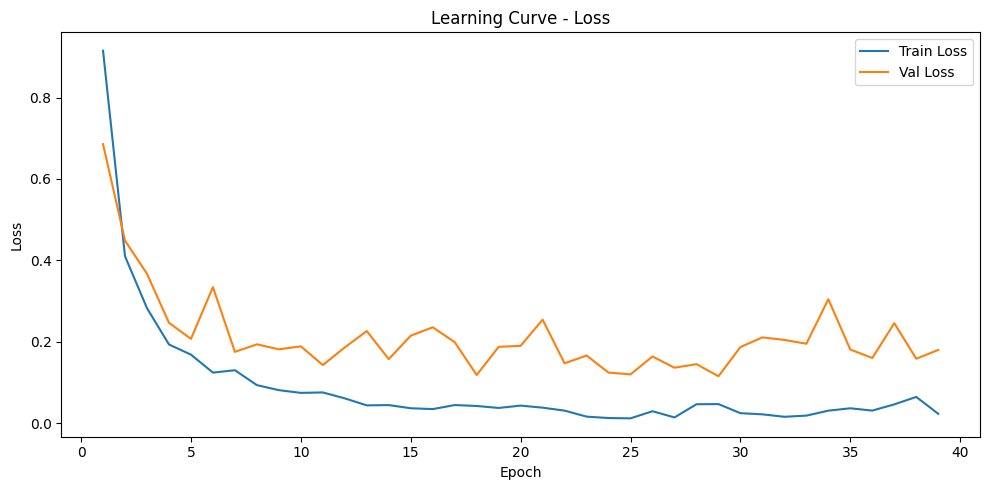

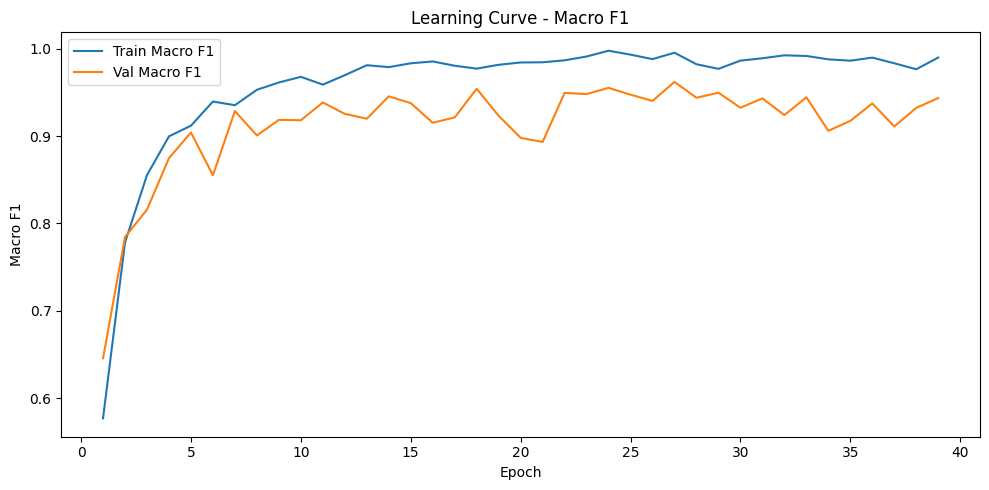

In [12]:

epochs_ran = range(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs_ran, history["train_loss"], label="Train Loss")
plt.plot(epochs_ran, history["val_loss"], label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Curve - Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(epochs_ran, history["train_macro_f1"], label="Train Macro F1")
plt.plot(epochs_ran, history["val_macro_f1"], label="Val Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Learning Curve - Macro F1")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

history_df = pd.DataFrame(history)
history_df.to_csv(METRIC_DIR / "training_history.csv", index=False)


### Bước 13. Đánh giá mô hình tốt nhất trên tập validation và test
- Nạp lại mô hình tốt nhất
- Tính accuracy, precision, recall, macro F1
- Tính AUC đa lớp theo chiến lược one-vs-rest
- In classification report


In [13]:

best_model = MLPClassifier(
    input_dim=X_train_final.shape[1],
    num_classes=num_classes,
    dropout=DROPOUT
).to(DEVICE)

best_model.load_state_dict(torch.load(MODEL_DIR / "best_mlp_model.pt", map_location=DEVICE))

def evaluate_full(model, loader, split_name="test"):
    y_true, y_pred, y_prob = predict_proba(model, loader)

    acc = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))
    try:
        auc_macro_ovr = roc_auc_score(y_true_bin, y_prob, average="macro", multi_class="ovr")
    except:
        auc_macro_ovr = np.nan

    summary = pd.DataFrame([{
        "split": split_name,
        "accuracy": acc,
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": macro_f1,
        "auc_macro_ovr": auc_macro_ovr
    }])

    report_dict = classification_report(
        y_true, y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )
    report_df = pd.DataFrame(report_dict).transpose()

    return y_true, y_pred, y_prob, summary, report_df

val_true, val_pred, val_prob, val_summary, val_report = evaluate_full(best_model, val_loader, "validation")
test_true, test_pred, test_prob, test_summary, test_report = evaluate_full(best_model, test_loader, "test")

display(val_summary)
display(test_summary)


,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,validation,0.970899,0.958614,0.965909,0.962004,0.998158


,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,test,0.934037,0.905054,0.912702,0.908452,0.994147


### Bước 14. Lưu kết quả chi tiết ra file CSV
- summary metrics
- classification report từng lớp


In [14]:

all_summary = pd.concat([val_summary, test_summary], ignore_index=True)
all_summary.to_csv(METRIC_DIR / "summary_metrics.csv", index=False)

val_report.to_csv(METRIC_DIR / "classification_report_validation.csv")
test_report.to_csv(METRIC_DIR / "classification_report_test.csv")

print("Đã lưu metric vào:", METRIC_DIR)


Đã lưu metric vào: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex02\run01\metrics


### Bước 15. Vẽ confusion matrix trên tập test

Confusion matrix giúp quan sát:
- lớp nào dự đoán tốt
- lớp nào dễ nhầm với nhau
- tác động của mất cân bằng lớp


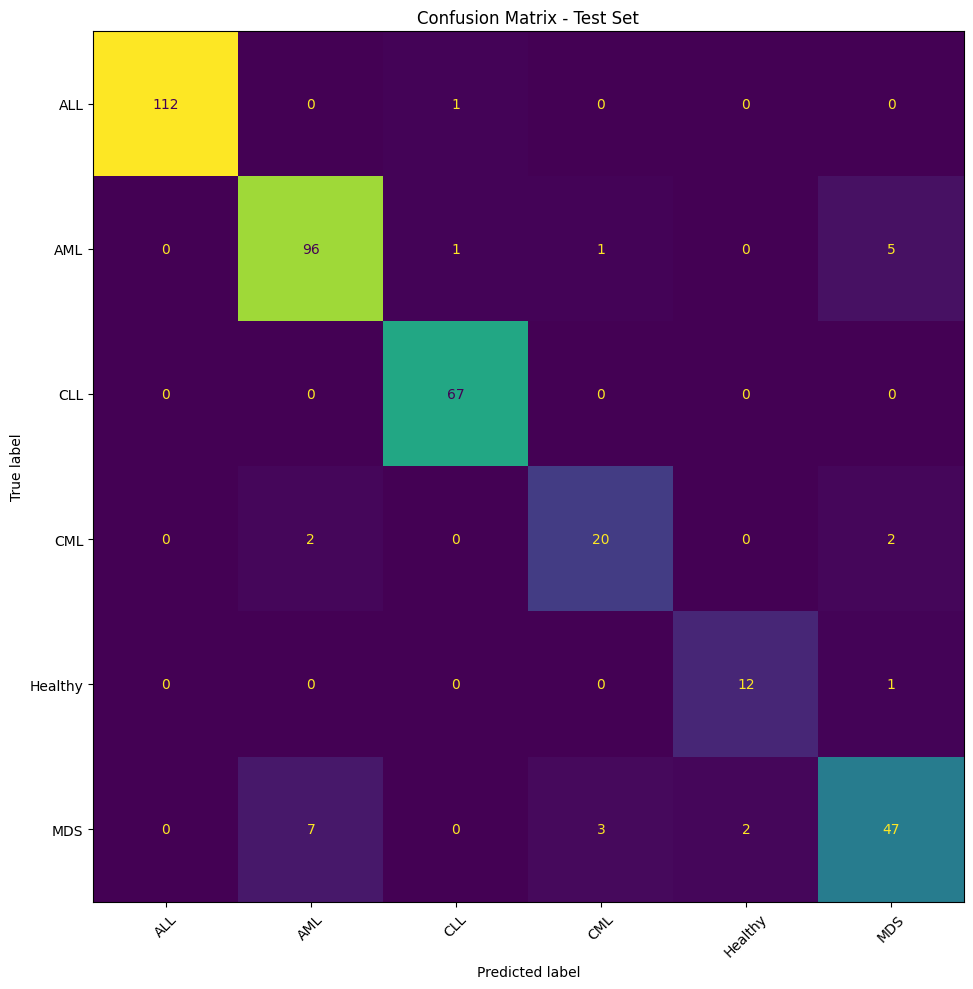

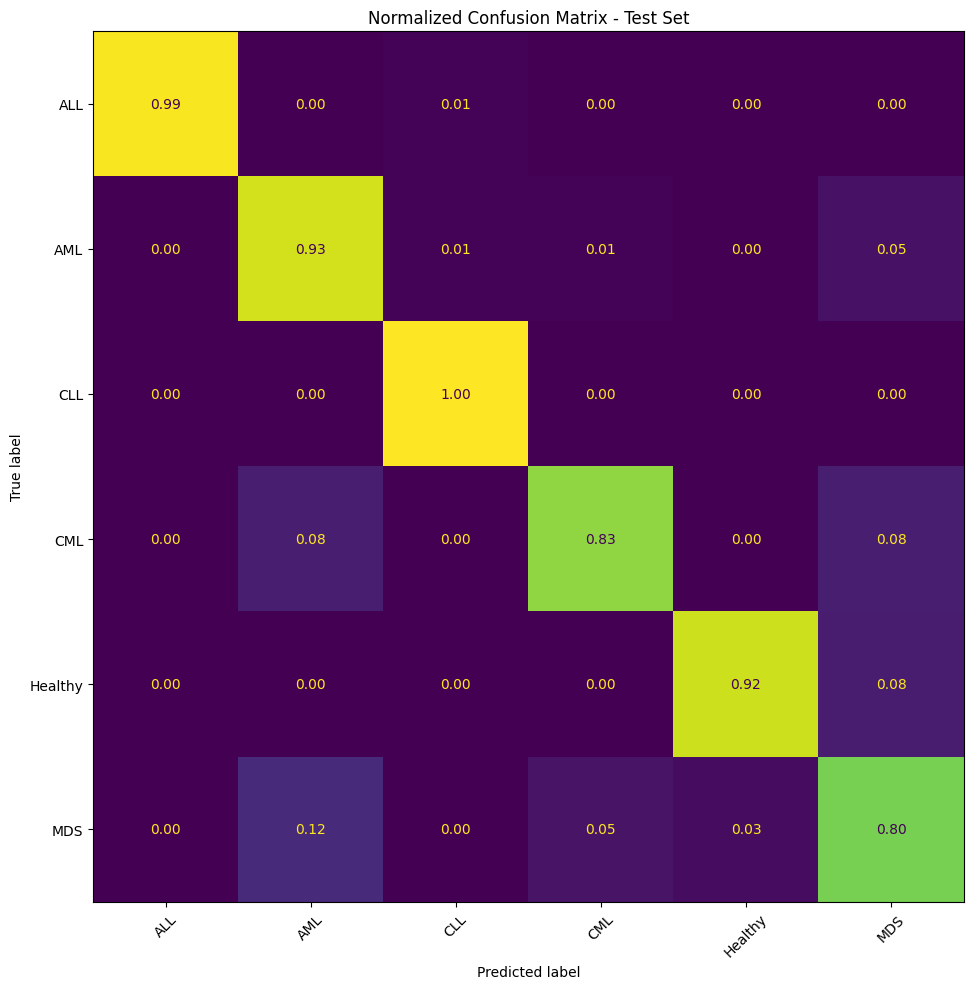

In [15]:

cm = confusion_matrix(test_true, test_pred)
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(METRIC_DIR / "confusion_matrix_test.csv")

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()

cm_norm = confusion_matrix(test_true, test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
plt.title("Normalized Confusion Matrix - Test Set")
plt.tight_layout()
plt.savefig(FIG_DIR / "normalized_confusion_matrix_test.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 16. Tự động sinh vài nhận xét sơ bộ cho báo cáo

In [16]:

test_acc = float(test_summary["accuracy"].iloc[0])
test_f1 = float(test_summary["macro_f1"].iloc[0])
test_recall = float(test_summary["macro_recall"].iloc[0])
test_auc = float(test_summary["auc_macro_ovr"].iloc[0])

print("=== NHẬN XÉT SƠ BỘ ===")
print(f"- Accuracy trên tập test: {test_acc:.4f}")
print(f"- Macro F1 trên tập test: {test_f1:.4f}")
print(f"- Macro Recall trên tập test: {test_recall:.4f}")
print(f"- AUC macro OVR trên tập test: {test_auc:.4f}")

if test_acc - test_f1 > 0.10:
    print("- Chênh lệch giữa Accuracy và Macro F1 khá lớn -> mô hình có thể dự đoán tốt hơn ở các lớp nhiều mẫu, nhưng còn yếu ở các lớp ít mẫu.")
else:
    print("- Accuracy và Macro F1 không chênh lệch quá lớn -> mô hình đang giữ được mức cân bằng tương đối giữa các lớp.")

if min(class_counts.values) < 20:
    print("- Có lớp rất ít mẫu -> đây là nguyên nhân phổ biến làm giảm recall/F1 ở một số lớp hiếm.")

if history["train_loss"][-1] < history["val_loss"][-1]:
    print("- Train loss thấp hơn val loss -> có dấu hiệu overfitting ở mức độ nhất định, cần theo dõi thêm.")
else:
    print("- Chưa thấy dấu hiệu overfitting quá rõ chỉ qua loss cuối cùng.")


=== NHẬN XÉT SƠ BỘ ===
- Accuracy trên tập test: 0.9340
- Macro F1 trên tập test: 0.9085
- Macro Recall trên tập test: 0.9127
- AUC macro OVR trên tập test: 0.9941
- Accuracy và Macro F1 không chênh lệch quá lớn -> mô hình đang giữ được mức cân bằng tương đối giữa các lớp.
- Train loss thấp hơn val loss -> có dấu hiệu overfitting ở mức độ nhất định, cần theo dõi thêm.


### Bước 17. Lưu mô hình hoàn chỉnh và kết thúc notebook

In [17]:

torch.save(best_model.state_dict(), MODEL_DIR / "final_best_model.pt")
print("Đã lưu model tại:", MODEL_DIR / "final_best_model.pt")
print("Hoàn thành toàn bộ pipeline.")


Đã lưu model tại: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex02\run01\models\final_best_model.pt
Hoàn thành toàn bộ pipeline.
